In [1]:
%load_ext autoreload
%autoreload 2

import glob

import cv2
import matplotlib.pyplot as plt
import numpy as np

from tflite_inference import TFLiteInferer

2024-10-11 14:49:04.362097: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-11 14:49:04.378075: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-11 14:49:04.382959: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-11 14:49:04.395028: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-11 14:49:05.318224: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [2]:
tst_img_path = "../../rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources/pg_object_detection/samples/img_320.bmp"

img = cv2.cvtColor(cv2.imread(tst_img_path), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 320
RATIO = W / ORIGIAL_W

In [3]:
def draw(img, detections):
    tmp = img.copy()
    for box in detections:
        cv2.rectangle(tmp, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 1)

    for p in detections:
        cv2.circle(tmp, (p[-2:] // RATIO).astype(int), 2, (255, 0, 0), 3)

    plt.figure(figsize=(8, 8))
    plt.imshow(tmp)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


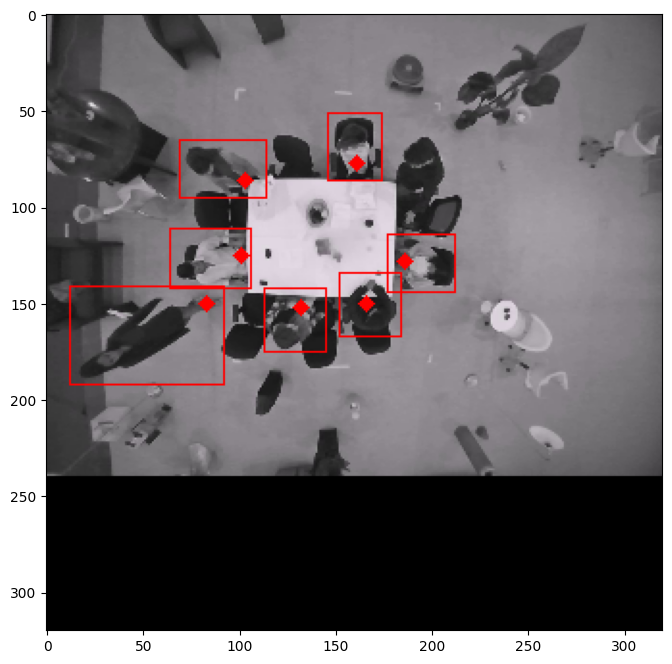

In [4]:

inferer = TFLiteInferer(
    yolo_pth="../../rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources_downloaded/pg_object_detection/backbone.tflite",
    head_pth="../../rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources_downloaded/pg_object_detection/head.tflite",
)

detections = inferer.infer(img)

draw(img ,detections)

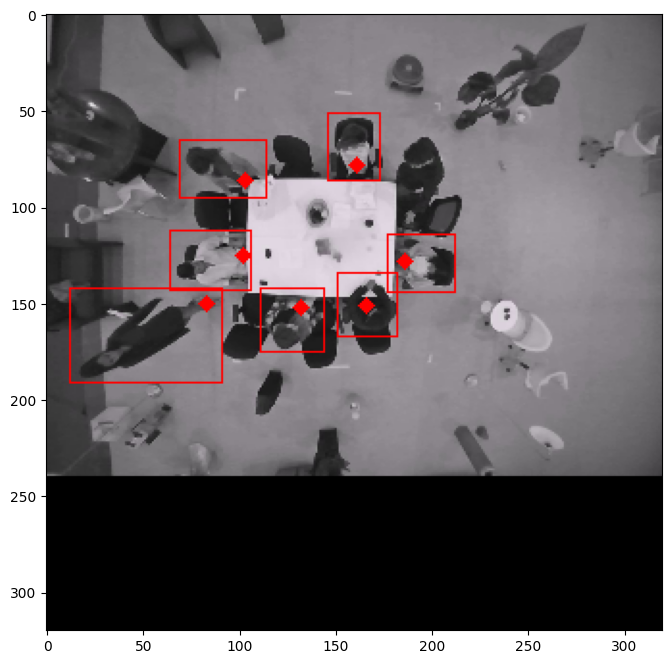

In [5]:
alif_output = """Box: [64.84 112.38 42.13 31.65]. Position: [102.86 125.58]. Confidence: 0.85
Box: [12.84 142.86 79.98 49.14]. Position: [83.24 150.22]. Confidence: 0.82
Box: [146.67 51.86 27.73 35.72]. Position: [161.04 78.17]. Confidence: 0.81
Box: [177.94 114.09 35.11 30.38]. Position: [186.13 128.00]. Confidence: 0.81
Box: [151.99 134.31 31.60 33.71]. Position: [166.91 151.60]. Confidence: 0.81
Box: [69.43 65.60 45.68 30.46]. Position: [103.15 86.17]. Confidence: 0.76
Box: [111.93 142.87 33.29 33.19]. Position: [132.15 152.40]. Confidence: 0.65"""

detections = []
for line in alif_output.split("\n"):
    line = line.replace("[", "").replace("].", "").split(" ")
    tmp_det = [
        line[1],
        line[2],
        line[3],
        line[4],
        line[9],
        "0",
        line[6],
        line[7],
    ]
    detections.append([float(i) for i in tmp_det])

draw(img, np.array(detections))